In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_v2 import Moire
import utils

In [65]:
sys = Moire(theta_deg=1.5, psi_deg=26.0, V=6.6, n_shells=10)

First theta:  0.4449719092257397
Last theta:  1.4071247279470287


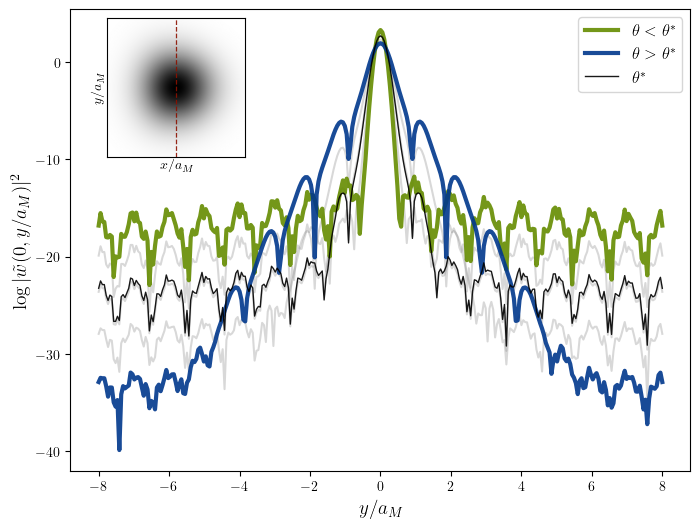

In [68]:
scale = 8.0
Nx = 301
Ny = 301
resk = 18
thetasquare = np.logspace(np.log10(0.03), np.log10(0.3), 5)

fig, ax = plt.subplots(figsize=(8, 6))

# ============================================================
# Main plot: line cuts at x = 0 for a range of theta^2/V
# ============================================================
for th in thetasquare:
    sys.theta_deg = np.sqrt(th * sys.V)
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell(Nx=resk, Ny=resk)

    wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.zeros(2), gauge_fixed=True)
    density = np.abs(wannier) ** 2

    ix0 = np.argmin(np.abs(x))
    density_cut = density[:, ix0]

    if th == thetasquare[0]:
        ax.plot(y / sys.aM, np.log(sys.aM**2 * density_cut), color="#658C00", alpha=0.9, zorder=10, linewidth=3, label=f"$\\theta < \\theta^*$")
        print("First theta: ", sys.theta_deg)
    elif th == thetasquare[-1]:
        ax.plot(y / sys.aM, np.log(sys.aM**2 * density_cut), color="#00378C", alpha=0.9, zorder=10, linewidth=3, label=f"$\\theta >  \\theta^*$")
        print("Last theta: ", sys.theta_deg)
    else:
        ax.plot(y / sys.aM, np.log(sys.aM**2 * density_cut), color="gray", alpha=0.3)

# critical angle curve
theta_c = np.sqrt(0.09 * sys.V)
sys.theta_deg = theta_c
x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
k_points = sys.mesh_k_unit_cell(Nx=resk, Ny=resk)

wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.zeros(2), gauge_fixed=True)
density = np.abs(wannier) ** 2

ix0 = np.argmin(np.abs(x))
density_cut = density[:, ix0]
ax.plot(y / sys.aM, np.log(sys.aM**2 * density_cut), color="k", alpha=0.9, zorder=10, linewidth=1, linestyle="-", label=f"$\\theta^*$")

ax.set_xlabel(r'$y / a_M$', fontsize=14)
ax.set_ylabel(r'$\log|\tilde{w}(0, y/a_M)|^2$', fontsize=14)
# ax.set_xlim([-2.5, 2.5])
#ax.set_ylim([-12, 4])
ax.legend(fontsize=12)

# ============================================================
# Inset: 2D Wannier density at theta_c
# ============================================================
axins = ax.inset_axes([0.02, 0.68, 0.3, 0.3])  # [x0, y0, w, h] in axes fraction

scale_in = 0.3
sys.theta_deg = theta_c
x_in = np.linspace(-scale_in * sys.aM, scale_in * sys.aM, Nx)
y_in = np.linspace(-scale_in * sys.aM, scale_in * sys.aM, Ny)
X_in, Y_in = np.meshgrid(x_in, y_in)
k_points = sys.mesh_k_unit_cell(Nx=resk, Ny=resk)

ix0_in = np.argmin(np.abs(x_in))

im = sys.plot_wannier_function(axins, X_in, Y_in, k_points, cmap="gray_r")
axins.axvline(x_in[ix0_in], color="#8C1100", ls="--", lw=0.9, alpha=0.9)
axins.set_aspect('equal')

aM_i = sys.aM
axins.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
axins.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
axins.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
axins.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
axins.set_xlabel(r'$x/a_M$', fontsize=10, labelpad=1)
axins.set_ylabel(r'$y/a_M$', fontsize=10, labelpad=1)
axins.set_xticklabels([])
axins.set_xticks([])
axins.set_yticklabels([])
axins.set_yticks([])
axins.set_title("")  # clear any title set by plot_wannier_function
axins.tick_params(labelsize=8)
plt.savefig("plots/line_cut_y.pdf", dpi=300, bbox_inches='tight')
plt.show()

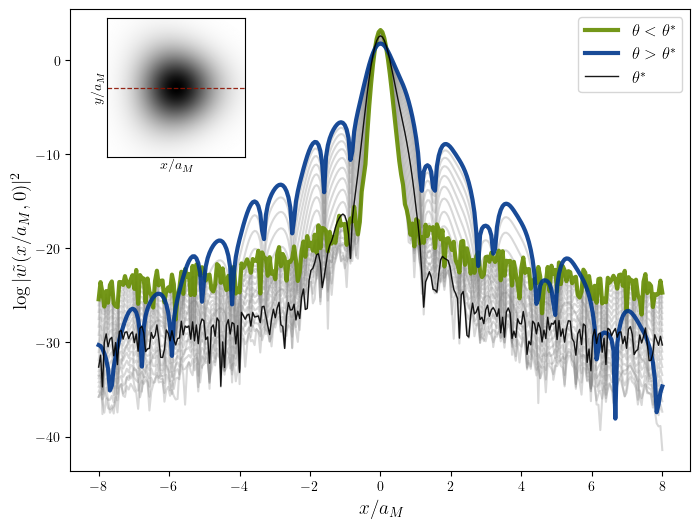

In [61]:
scale = 8.0
Nx = 301
Ny = 301
thetasquare = np.logspace(np.log10(0.03), np.log10(0.3), 20)

fig, ax = plt.subplots(figsize=(8, 6))

# ============================================================
# Main plot: line cuts at x = 0 for a range of theta^2/V
# ============================================================
for th in thetasquare:
    sys.theta_deg = np.sqrt(th * sys.V)
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

    wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.zeros(2), gauge_fixed=True)
    density = np.abs(wannier) ** 2

    iy0 = np.argmin(np.abs(y))
    density_cut = density[iy0, :]

    if th == thetasquare[0]:
        ax.plot(x / sys.aM, np.log(sys.aM**2 * density_cut), color="#658C00", alpha=0.9, zorder=10, linewidth=3, label=f"$\\theta < \\theta^*$")
    elif th == thetasquare[-1]:
        ax.plot(x / sys.aM, np.log(sys.aM**2 * density_cut), color="#00378C", alpha=0.9, zorder=10, linewidth=3, label=f"$\\theta >  \\theta^*$")
    else:
        ax.plot(x / sys.aM, np.log(sys.aM**2 * density_cut), color="gray", alpha=0.3)

# critical angle curve
theta_c = np.sqrt(0.09 * sys.V)
sys.theta_deg = theta_c
x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

wannier = sys.wannier_wavefunction(X, Y, k_points, R0=np.zeros(2), gauge_fixed=True)
density = np.abs(wannier) ** 2

iy0 = np.argmin(np.abs(y))
density_cut = density[iy0, :]
ax.plot(x / sys.aM, np.log(sys.aM**2 * density_cut), color="k", alpha=0.9, zorder=10, linewidth=1, linestyle="-", label=f"$\\theta^*$")

ax.set_xlabel(r'$x / a_M$', fontsize=14)
ax.set_ylabel(r'$\log|\tilde{w}(x/a_M, 0)|^2$', fontsize=14)
# ax.set_xlim([-2.5, 2.5])
# ax.set_ylim([-12, 4])
ax.legend(fontsize=12)

# ============================================================
# Inset: 2D Wannier density at theta_c
# ============================================================
axins = ax.inset_axes([0.02, 0.68, 0.3, 0.3])  # [x0, y0, w, h] in axes fraction

scale_in = 0.3
sys.theta_deg = theta_c
x_in = np.linspace(-scale_in * sys.aM, scale_in * sys.aM, Nx)
y_in = np.linspace(-scale_in * sys.aM, scale_in * sys.aM, Ny)
X_in, Y_in = np.meshgrid(x_in, y_in)
k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

iy0_in = np.argmin(np.abs(y_in))

im = sys.plot_wannier_function(axins, X_in, Y_in, k_points, cmap="gray_r")
axins.axhline(y[iy0], color="#8C1100", ls="--", lw=0.9, alpha=0.9)   # line at y ≈ 0
axins.set_aspect('equal')

aM_i = sys.aM
axins.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
axins.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
axins.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
axins.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
axins.set_xlabel(r'$x/a_M$', fontsize=10, labelpad=1)
axins.set_ylabel(r'$y/a_M$', fontsize=10, labelpad=1)
axins.set_xticklabels([])
axins.set_xticks([])
axins.set_yticklabels([])
axins.set_yticks([])
axins.set_title("")  # clear any title set by plot_wannier_function
axins.tick_params(labelsize=8)
plt.savefig("plots/line_cut_x.pdf", dpi=300, bbox_inches='tight')

plt.show()